In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Load dataset (encoding='ISO-8859-1' handles special characters in Online Retail)
df = pd.read_csv('data.csv', encoding='ISO-8859-1')
print("Initial Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

# 2. Clean data: drop missing CustomerIDs, remove cancelled orders (InvoiceNo starting with 'C'), and keep positive Quantity/UnitPrice
df = df.dropna(subset=['CustomerID'])
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['CustomerID'] = df['CustomerID'].astype(int)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Calculate TotalPrice per transaction line
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
print("\nCleaned Shape:", df.shape)

# 3. Create RFM (Recency, Frequency, Monetary) features per customer
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
    'InvoiceNo': 'nunique',                                   # Frequency
    'TotalPrice': 'sum'                                       # Monetary
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']
print("\nRFM Descriptive Statistics:\n")
display(rfm[['Recency', 'Frequency', 'Monetary']].describe())
rfm.head()

Initial Shape: (541909, 8)

Missing Values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Cleaned Shape: (397884, 9)

RFM Descriptive Statistics:



,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


### Observation — Data Cleaning & RFM Feature Engineering
* **Data Cleaning:** Removed transactions with missing `CustomerID` values, cancelled invoices (prefixed with `'C'`), and non-positive quantities/prices to ensure accurate customer metrics.
* **RFM Metrics:** Aggregated transaction history into three core behavioral features for each unique customer:
  * **Recency:** Days since the customer's last purchase.
  * **Frequency:** Total number of unique invoices/orders placed.
  * **Monetary:** Total lifetime revenue generated by the customer.


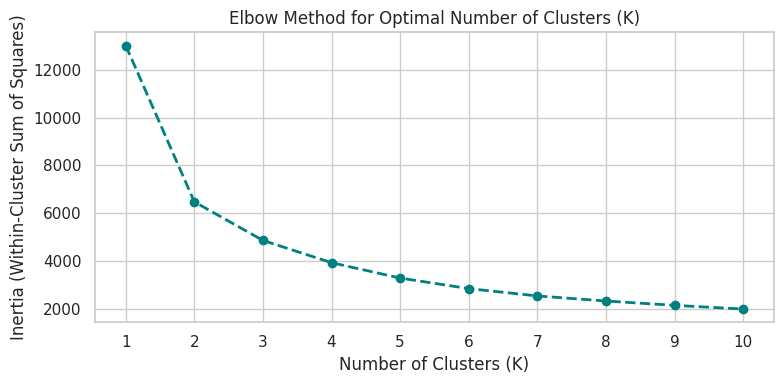

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Log-transform skewed RFM features before scaling
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

# Standardize features using StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Elbow Method to find optimal K (testing K = 1 to 10)
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='teal', linewidth=2)
plt.title('Elbow Method for Optimal Number of Clusters (K)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(K_range)
plt.tight_layout()
plt.show()

### Observation — Feature Scaling & Elbow Method
* **Standardization:** Applied log transformation (`np.log1p`) to handle right-skewed monetary/frequency distributions, followed by `StandardScaler` so all three RFM features contribute equally to clustering.
* **Optimal Clusters ($K$):** The Elbow curve shows a clear bend at **$K = 4$**, indicating that 4 distinct customer segments provide a strong balance between cluster compactness and interpretability.

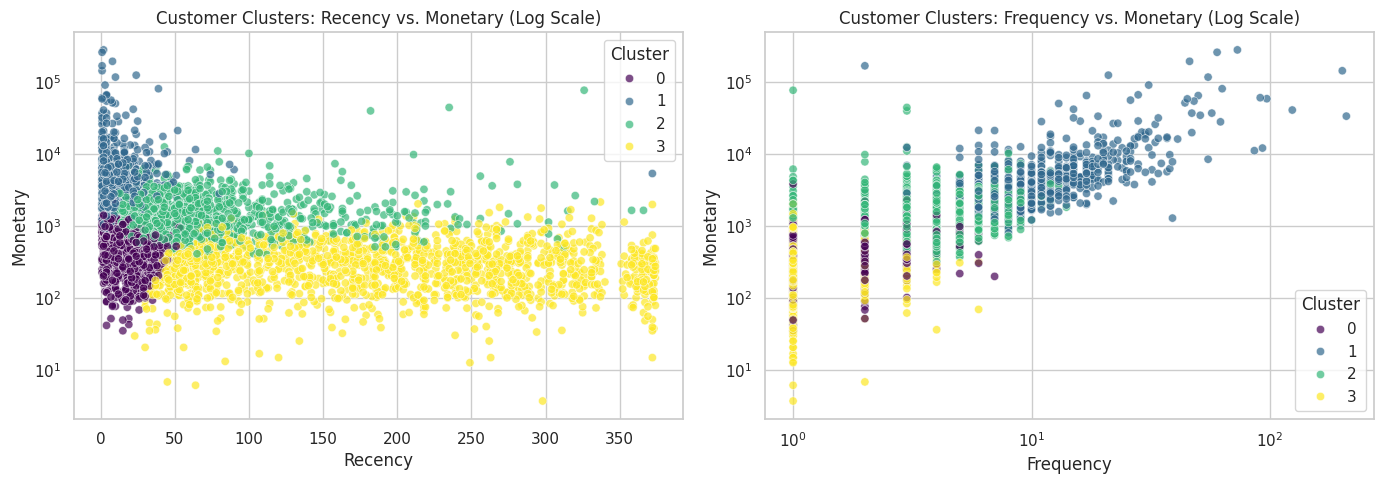

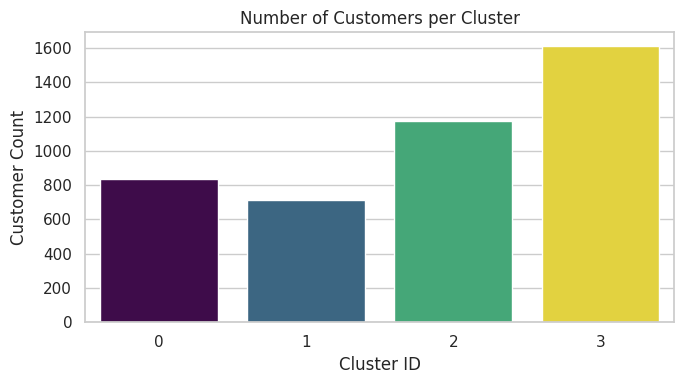

Cluster Profiles (Mean RFM Values):



,Customer_Count,Mean_Recency,Mean_Frequency,Mean_Monetary
Cluster,,,,
0,837,18.12,2.15,551.82
1,716,12.13,13.71,8074.27
2,1173,71.08,4.08,1802.83
3,1612,182.50,1.32,343.45


In [3]:
# Fit final K-Means model with K=4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

# Scatter plots for 2 feature combinations (Recency vs Monetary, Frequency vs Monetary)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Cluster', palette='viridis', alpha=0.7, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Customer Clusters: Recency vs. Monetary (Log Scale)')

sns.scatterplot(data=rfm, x='Frequency', y='Monetary', hue='Cluster', palette='viridis', alpha=0.7, ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Customer Clusters: Frequency vs. Monetary (Log Scale)')

plt.tight_layout()
plt.show()

# Bar chart: Number of customers per cluster
plt.figure(figsize=(7, 4))
sns.countplot(data=rfm, x='Cluster', hue='Cluster', palette='viridis', legend=False)
plt.title('Number of Customers per Cluster')
plt.xlabel('Cluster ID')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()

# Cluster Profiling: Mean RFM values and customer count per cluster
cluster_profile = rfm.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Mean_Recency=('Recency', 'mean'),
    Mean_Frequency=('Frequency', 'mean'),
    Mean_Monetary=('Monetary', 'mean')
).round(2)

print("Cluster Profiles (Mean RFM Values):\n")
display(cluster_profile)

## Cluster Profiles & Actionable Marketing Recommendations

Based on the mean Recency, Frequency, and Monetary values across the 4 clusters, the customer base divides into four actionable segments:

1. **Champions / VIP Loyalists (Lowest Recency, Highest Frequency & Monetary):**
   * *Profile:* Purchased very recently, shop frequently, and generate the highest lifetime revenue.
   * *Marketing Action:* Enroll in a VIP loyalty tier with early access to new arrivals, exclusive bundles, and referral rewards rather than heavy discounting.
2. **Potential Loyalists / Active Mid-Tier (Low-to-Moderate Recency, Moderate Frequency & Spend):**
   * *Profile:* Recent buyers with steady purchase frequency who have room to grow their basket size.
   * *Marketing Action:* Use personalized product recommendations and tiered spend thresholds (e.g., *"Spend 50 more for free shipping"*) to increase order frequency and average order value.
3. **At-Risk / Slipping Customers (High Recency, Moderate Past Frequency/Spend):**
   * *Profile:* Previously active customers who have not purchased in several months.
   * *Marketing Action:* Trigger automated win-back email campaigns featuring time-limited discount vouchers and restock reminders based on past purchase categories.
4. **Hibernating / Low-Value One-Time Buyers (Highest Recency, Lowest Frequency & Monetary):**
   * *Profile:* Single-order shoppers from long ago with low total spend.
   * *Marketing Action:* Include in low-cost seasonal clearance broadcasts; avoid spending high paid-ad budgets on retargeting unless they re-engage organically.